# CatBoost · clock proxy: три дополнительных признака

Готовые результаты двух вариантов CatBoost с clock proxy: исходные признаки и исходные + три быстрых.

**Обучать ничего не нужно.** Таблицы и предсказания уже включены в ноутбук. Он работает самостоятельно, в том числе в Colab; достаточно NumPy, pandas, matplotlib и scikit-learn. Рисунки уже показаны ниже. Для редактирования подписи меняются в ячейке `TEXTS` или непосредственно в ячейках построения.

## Как получены результаты

- 31 участник, 25 481 эпоха по 30 секунд; сон / бодрствование.
- 31 разбиение leave-one-subject-out: тестовый участник полностью исключён из обучения.
- 100 деревьев, глубина 4, learning_rate=0,1, l2_leaf_reg=3, random_seed=0, веса классов balanced.
- Порог вероятности сна **0,5**; сглаживания предсказаний нет.
- Это текущая конфигурация `FAST=True`, но проверка выполнена на всех участниках, без сокращения выборки. Поиска гиперпараметров не было.
- Финальные веса на всех участниках сохранялись отдельно и не использовались для получения этих оценок.


In [1]:
# Подписи графиков и названия метрик можно редактировать здесь.
TEXTS = {
    "base": "Исходные",
    "fast": "+3 быстрых",
    "auc": "ROC AUC",
    "kappa": "Cohen κ",
    "accuracy": "Accuracy",
    "sleep_correct": "Сон распознан",
    "wake_correct": "Бодрствование распознано",
    "means_title": "CatBoost · clock proxy · средние по участникам · LOSO, порог 0,5",
    "delta_title": "Изменение κ у каждого участника: +3 быстрых − исходные",
    "roc_title": "ROC · объединённые тестовые эпохи",
    "pr_title": "Precision–Recall для бодрствования",
    "confusion_title": "Ошибки при фиксированном пороге 0,5",
}
COLORS = {"base": "#64748b", "fast": "#0f766e"}


In [2]:
import base64, gzip, io, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix
from pathlib import Path
EXPORT_DIR = Path("catboost_analysis_exports")
EXPORT_DIR.mkdir(exist_ok=True)
TABLE_PAYLOAD = "H4sIAGDuzGoC/72by44bW3JFf4WoqXWl837YE8NtA54YMAx4ZDQKycykir5UsUCybrdwIcD2tL/GA/9H64+84iRZlc+mmmZbJVEsJpmZcSJi7x0Rh78+vFSH07bevlTPp8cv7emwrY8Pf736t18fNm11ej20j8f2xAsP/7Q/bffPH1b/+C8fVr/Z7eufHz6sHo6v639vazluvcreOF5rX/b1k5zDac+v1WvNc/Uxex2sjuryyKGfq5eXqhwMPvoQvNNRhxicnKaq69dDVX/tPqw5bIJXQRmnsnz4uGvbl8d6fzh0N8CbrNYmuxh8csoY3vO76ud28JakYsjGXh7jtw+rP9dQr61x5Q7eDQ22b6jKWWvvDJdw1g3sNDYlnW3K2jlry1kGdkZj+aDWIVgVwoKdUXlrgzOBs2hv9ZyhOaTob7BOc1lvUt+6pOPAOqO0TVarpL0eWse9mGiSTlallLIfW5eCt0Gz7FqXU8x7UXPu6LVWzgfv3Zx1rA4rG5MJKoXsb3Kjyyko2zc0uqEbVbD4K7gkzhoY6lxKijAwMUW8MQlXbIuEuTFOgjmkWUMT6WIty6WUi11MTwyNrIQjJ3JixYy6xVATLPeq+oZml/qG2oBLFetpI8/MMDEJRW2jS06nrCbxyiIlJzGd8JVb8Gf0vZ95M1MKuvdwi5k+J1wxCFyv+2aCDTkrbYgpsGRgpfbZBV512eho3MTM5FNO2eFwFQj7sODPHHG5VUb7ZKKdxR/yG4jShAc+9+mWwCVznBkYmqPrG5oViZHwpOW+i6t7KZqyScqESHQ75fPEoV5H521kMUPMIc671OtEUPpIcBI5aRaAHG+Jb4+3WKqd9zYPI9f3LQUAYgQEAzhoCtm8G2q9JzRzTvyHNVOPRufA50QAs0zzdhLXQWXNRaETAmAWilTUznCG8+MNdrKGCTQdMEpHDWc7obNgyQyoz+ZshrELLOiUosvORpVK+g4pRcfo4BzvMDTqBUaBdgkIZ1nN7lZmqNNrHHl5NDcYmjNY4gbkAhUMNEJK3CiGQCB6pBFIPgIz5Qg/QMJTdkE8EN7CTDhLz4NuCWzxasZvZi509Ud1U6w6wmTIm6kvf6JXEcaQixb2GvpQ5xhUIIiJV5PtxDSjLKIBXpWgjm4Bf6xFXKGSrJxqFn98cLb/7wZLk/Gs9DAry69vTjQ54KQgGRF1GkoEhzri0oCoCybZKdLiHgMHgKXIJL1AKSxhRv648n+cZRSUCCeRLA8k1y1SKGKmD0M7+0ooJUzApT5AnDkOg1XuLgLBphiiJx6NQiURfIvWY4qdD1YDgmlhZwiDGJlNSwQZaXt5cLekJaLPxaGloe9RYDDECJkoVluPLY2WsOQAq51UnuHOaDDi8meBURT6o2hasj7ZWUshPZNYLkIchZlvCd2AWhwmafaDGgU/JsyBGRWmDKkTue6DwI+kcZgyCvIRwnK8IZHHeT5Hg2hgFH6wEJSbl+4x+4yFhJXjdm+xEwRAfQ7BqC/5EAE6cLPcAnCpxqFLyhRGZS3yDKEQ9fjh8nc+RYGzKFVOLoimZlU83G3QtJfHW8AIOhQRMPToQNziYG4BatbQpBmCkUbWopRgPFF+cZqkJCjcCZTAWsEtJCkFSFC80cKyKuZ7MQqecbpkQi8rB2SJ5CFSFOStgNoRWZLRFKAKBLECuNNoRWYr6ivQS3cpPZeVVnuoXiQUtd6sdCecwUF9ebwlLTVk7aL+E04EfaJgAwWbjUWsvVuqHBGM8okId3TtpBYDZa3kHESA6J7XP6wBZIIyNigPsvNuPpQ7SnbIIQPL0J8G+M/Zee1H1bQie4AShCyQ4OKUKpMXJRaFY6inlySs7v2bbYqQoYgTyh7qP1FdtyAO/IRv/gSyUjIEKk2yRecwSsPMAggTJtyHAp0KO7S3YD9RobU384YCaIQoAEu4zncNRBoSBzjZJ0j1lpKEMIQtB8WX1kO8iWh0SmlgxWg1NBSBDelTVgUyNsxQpRnovAUFSwbcKz49fKfckPntgCiAPQW6sLLIRZNHJVaQVg3rQWHt9dRvAaK01kkLgxJ1QbVSNhO8ol0RXNot1FgU6BI9lAXhNsf53GmP9xKrBNI7mFL2KtLRCqyOmF8rcCFLIgI+qPgJxIB8ilx3iKQYFiBmIF7UvJYbtgduSkQFnadhd8AP1DlwLoxLtkk9OKJ+qdThQiutS22mpAEZ4HMPtUu3aEniKPxNGnoq/7yQiYOfWzROIFe8N8vNgSQiRmiZiDYjzkBTUxBTnChrsDRPa2afrZFa2ElRttSGBbQQrUmVZ36+39NvN4ebRCtVuR/IgDRoDoCzBA1iAYYWEh7KAMpOGMIG8XaYaYNgoSLxLu2LeY8i+qlvTST3QK1ZGYAG8ghG0Lu0Zm9JUdQN0DeUAYOOLCIEBosxSJc8jwSPhVhBERMpuYTMppYmyT5UvayIXQjd0pS7ZOEsWbKIWWAN2DfxttaztqxjGqKuGZIlaFWSx2hq5VEFLe7ArdpQPzgzlQXce+z9nbcUvUV5ivAiyrvW2dSlKCFiS5MGSXrEt+ifYN1AFHg/aLFrcVqSVj9ZNAJd1gBPh9LfU2HqzyhdHEcCS8llFtQPK2lk5gJFIZNnzQQIZXJ1edQ31ZVZhj1DGh00f6KRgVBAHRjydGQocqX3M5XqVJQGvWLxF3J9Xv4Qrqn/M9/8sYOfH7J09VerP/739z98/8/v//X9P77/4Y//8+eO/ZCm0qwJpZ8z6l0i96Q3mUT8mjhVEBlRKGwEeysblrpBznFUoAFg0PMDhtSvUXi8h+nXB4HUb6CqonRxPrtRx491IYepqygxp1ULFI3i8pTXCOtumDnDQKKIjQ1B2p4m/h8HgVfMvToZhHDBzAACB4zK42y2gqrwEMDWFavjepTqIycYwEnvd97TsLaKJDPw6MLCaFBmOVL3nquau3j66qywU8hK2vOpE/b9lqcIPrQTvK3CzLBQBmyG8KVc93nB1eJggg0Bar1IyFnT38aE3czwHqZfnx4CWRlSlR6BGw/1g6OcgVKRgmZa11FJSTlP5pfafsHluv8zP5kAJXLv4S52Xx0nevGHTKCDoPIw2uEcqXMBJDjKqul2BiXeJorBrhhVWui+UDGQE5G0IqfS3eaJ16L96oARSMMZ1OzcfcgjMmNZpIyQGaRTaYro4kVSQvqoasnnPYu6nt1Mk1SmCG+P90G4q/PGLDTrytsQZqM5nJOaCHmKTkaIz1TDQUBOaknjbViYIWfCQdbn3OyepXEWXSPOzo/xHqZfH0Em7FLS+Ebmq2zGkznYB1dEVWaqM2RWcED6eND9QseY5XMi6KTy5HJ36xhfMf0HhpJWth2R705TS43UuEwkBfJBeD8H7tIIogKP1P6+m3fNFVghEBOcRs6zUDEPFIy9T7xfm1kKYyOpwJ8Q1Gizj+30rIe+kkwSppZDaok0kVK6mwDMWB79fIjLJOXt313k2vW5Jc6Notl0pmox47mltFmVCFWtlJ5WXZm0RwxLF1eGkgtbYQAGqlAduv/n68uu3OJWjRS79zD96iQTYcE1E8jizkKnx2WJqlk2KSnSQuVpr4RSNmbpCknhvbDXKb4NMZPAxHyvRDSUfX+4S3JfG21GUS7SVwSVccqoTRSlBnZemn+ma7uOS22V7PufBRon7Sl0ldQmbj67B63BpNxd4v3qsJPsjA5k8iKptRnPjxyHuSNUpQtxRsGwLFK1m7J0S2wm9WFG5UVpv9xr2nnN8mvjTyQZWK0RaMJl48pMQVY4QXosWc0MBYOV3Sdvf+fjnc9CljIDOO91nRncB/Tv++NdqvHr41CpEII2MuaC0oeZLt113EAh5lXXQxghOjaRv3A8SsgvtFxEB8GTinzR1t0+qbimWK6PR5N0OUByxFa2o/BOsj8OuPIyHYwznW60a3ZZtJhbmhrKfDtplCCaiEJ+fsZthzuO78LbV+elSSKX7MVL5HYazUthVC1JTQbo6SZdikhrKJ6RI6THQv8wZK+dNOfgSdbJ/+XcfHWCKpNhmwwgw334MOo6UIJGjOBOoadpNSK7sbyzHDdJLZWgmlDo/ZtFMSNxZKC35O5Uhl0fqQZQzHkhS0qBEWkTtEl2BaLOKKHzTDdcy2BcSlRB8oUmsUhxX2Se7Kj/izn5+lS1bJi/DFVHhVfyMpvLlMLFm1OqssOx6oKTzQI9vV1UJM59CuxrU9eso/AS3kN0T5SoljpEkdnUDGnq2XOvmypcRup6qbVAFU54CHWrPN9NkmzKsiHcWwTrXTT41Smsp8pSMm0lrpUaT2FT2awjqCtF9AS4cBHlDKnsQ7ALO13Bcht7GwHmty73ug/W36WFeH0uK0JKxomEWopptPWMRCzfHCFjpRKcOj27fqAuTNoBbBn6QPwpe3u3wewV069OaqXwUrINTXYThFG4y5csWBpqD5Gh04ZSBOFQZFyDDI5pHskgQZfeH9L/14jg6uzWOfk+lMW5hK4f73em8JK5rA7hvBl6vFtEauPL5vOFQZ8WBYT2Ru+kjj9mBn29yS1If5fC6+owVzZ6g9daWuvJDbuIDvWocWkpi6L2c9/HCEqUuOyiTYu79/tpbOd3r8nuE6G3LJt57+L0HxnvahICI3CeGw9KgD/ZEAPISVvFzGyqiar3d+mrKEa6GQG/cp35r8K9NxnKRum7qLUr896yR1m6K0oqztG0wMr2ZSDQWyT7dMd0VsrLcslmIqMWNmNm+eJVjsbId7byfKJH02+fhvvA+7UJMNoDIZZsRHaLJh0V29qQp6XklIH3zKb4KJsWHPxJJi+Z3v+alZ+fAEOb/Z9vv+VdL/v9rm2G3/38sm/anSzEb6rT3+33x5OY+yND8fe9Gl2n6OVRbuLc1At9DPvbrC5pOq6cLodCeu9FXV6T2JF70eXEb692czNe/VLVh/3l5dipurdLchNnb5hxTf52jLh405dvL9puwnO56uVl8LJDy5vWazam3vGxY4r+AqYBHLwv4GS//Jv9KoXJArrS+xstoLTu5hbQqDy7gF7bxQX0Ok8XMJWwniwgKF6C8Ev1vN20R1moXx9O1fFnWbES5J+K/RKn719ULlH6cN57IMfOs3h5ep5Tl1e7ua08Pc8xy9NutFfe0I26yse64Y88PQ9D5Ol5ONC9oXTL5em5lSxPu9ZqeWvXaizHu9Zbedr1ouTpuTlTrtA1L8ppu2K+vNrVuuVjXfFXrtAVR+V2u8KhvFqUdHlrpyzl6VlplVeL8ij31TFxuVbHTOVagtTdvRbkehAnnJ4O7fFpv2u6kJA1P+xP+3pfQtvqnzYcW+3a6pf2p/1z+9MZ/37av57+ZvW8X51w4KrnptX2eXU6VNvn7fNnuVZdndaSHI+/tIcjuSBn1R8Nyv7s3+rLsQTA9tQeKsmWUgoq0clc9SDneeRAlw4ST037cnoS4pF3mEfetHk8tJ+lFfaxtPqrw+7r4/G0f3kpn92/PjdyzufX3Y7Dh3azPT3unx83/M7Lm2p3bOX16rnZfyFx27IU3+Ted9Xx+Pi7dvv5qWTzutpVzzXH5dj+ebP9/LipSvyeDq9tnwhQaUUI9eCgs3IKoBLVX8qrctqnQzl5OSLu+QEAWT6BLHBbdRhdn7a/tN0bWK3dw2+/Xe63xwIP/1x4YSVwcDyuqt1u9dTuGnH26mzbMCn7n/3X526l+PyXtnq+nGSQwsJi7fNxy81sT18fs+qf4O/bY33YvsiNrvYvJRqeP69e9lui6tjuiDpO/XqUF0vU7ap1uzt+IApPq2pFWOz2X3nHe0QXNzWs/lNFfVjW/9AS3p+0Ko57PLvn+PFFSPdhs4mVfAemiZtgK9fmWId1m5yuU7WpGqfqKsW20l43ua7rvJGvo7e20qkxTYrlgt0F5s5eScvJxaYNIWyo2Br5mixlTtuus6tMYzh7akrzPLd2vamrTWqrRte2RUF0Z6+aZiuernaPnRq4XOPT4pHz1b2tm3ZTy3fYuTqQsglubZuoQtu0bh18bNYpgwoxRmu7ncvZb9ZmY83GNVVx3f71ULefKi7y9bg9fir5sd1s65K3n95SvcuN84VblsyH3GSva7VeVyYjEzboeNugexuvXUMRu26NtZUMy7gnp/w6hdpyS8CoBGrh2i6D3q8iMf64ro4CDQ+NeCwoR13UOLt2jba1b1CVpbFCKZV9U7UNa7/WtqlNrlq9rqo6Nq60fAdY1Z36nNsPar1RG6d1tZbv0wYPyCJY19V6vdloV6/XcV25ddpU2UROTMhoFt/mSjdVU5l1sWC/3/TjcA4HHgJ6cZ0b3ag2bZL2mZVp16GO6xrErqQVYFurKl9VemM20gaMoWlbXvAbm+qHHwWMB9/6ts0pb/ym0S3r0PiWO6+dqWxs41p2qDWQestaqjarhiC0vK9pa6oqWExMOm2/tJcwk5N2q0b4//5rgYnX9e4cGnL0H36/PZaELuxAnnZoAco8N+8o83Jom21daKDQy6G9kMlqf+C3kvM7fv34donjE0q297n3ZSbo165ODY7Pba1bX7NmxhgXknG2dpUQvVekXK2S7FXTdbsuhUpTJQKxfvj27X8BDomS6C1FAAA="
ARRAY_PAYLOAD = "..."
snapshot = json.loads(gzip.decompress(base64.b64decode(TABLE_PAYLOAD)))
participant = pd.DataFrame(snapshot["participant_metrics"])
pooled = pd.DataFrame(snapshot["pooled_metrics"])
with np.load(io.BytesIO(base64.b64decode(ARRAY_PAYLOAD)), allow_pickle=False) as stored:
    arrays = {k: stored[k] for k in stored.files}
means = participant.groupby("feature_set")[["auc", "kappa", "accuracy", "sleep_correct", "wake_correct"]].mean()
def feature_set(base, extra=False):
    return f"Motion, HR, {base}" + (" + быстрые" if extra else "")
def name_for(name):
    return "Clock proxy" + " · " + TEXTS["fast" if "быстрые" in name else "base"]


## 1. Основные результаты: каждый участник имеет равный вес

Для каждого человека метрики рассчитаны по его отложенным предсказаниям, затем усреднены по 31 участнику.


,ROC AUC,Cohen κ,Accuracy,Сон распознан,Бодрствование распознано
feature_set,,,,,
"Motion, HR, Clock",0.9119,0.3771,0.8278,0.8324,0.8106
"Motion, HR, Clock + быстрые",0.9218,0.4094,0.8506,0.8596,0.8074


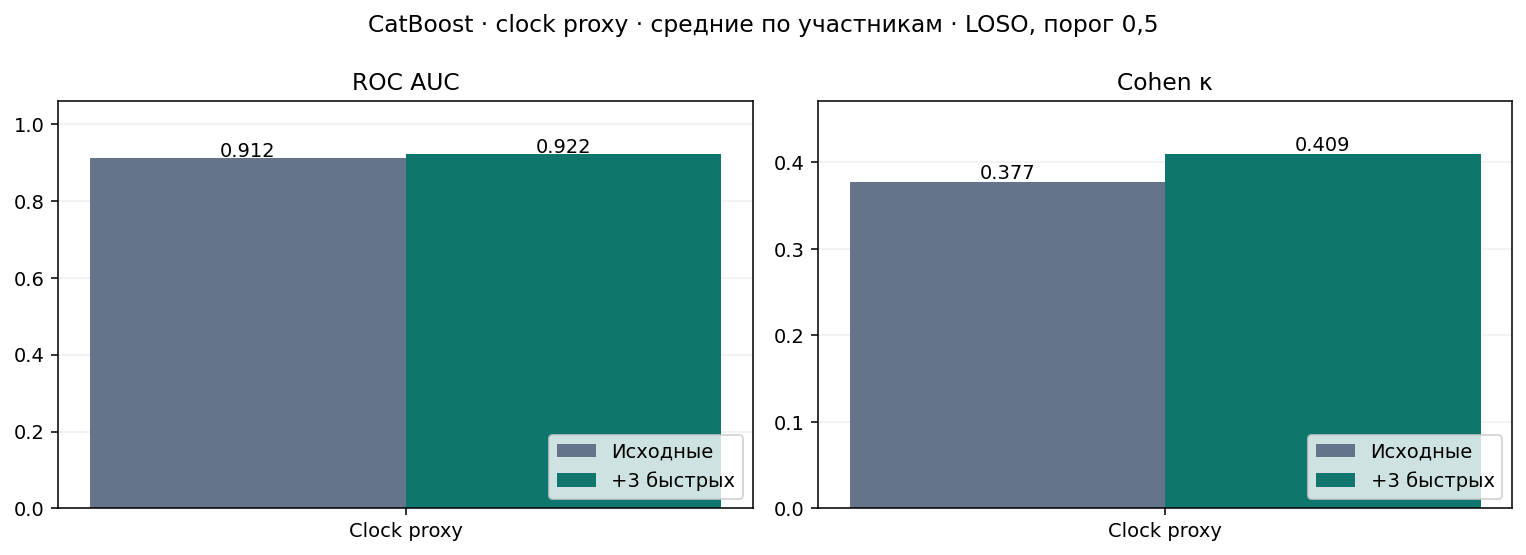

In [3]:
display(means.rename(columns={k: TEXTS[k] for k in means.columns}).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["auc", "kappa"]):
    for i, base in enumerate(["Clock"]):
        for extra, offset in [(False, -.18), (True, .18)]:
            key = "fast" if extra else "base"
            value = means.loc[feature_set(base, extra), metric]
            ax.bar(i + offset, value, width=.36, color=COLORS[key], label=TEXTS[key] if i == 0 else None)
            ax.text(i + offset, value + .004, f"{value:.3f}", ha="center")
    ax.set_xticks([0], ["Clock proxy"])
    ax.set_title(TEXTS[metric])
    ax.set_ylim(0, means[metric].max() * 1.15)
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
fig.suptitle(TEXTS["means_title"])
fig.tight_layout()
fig.savefig(EXPORT_DIR / "mean_metrics.png", dpi=180)
plt.show()


**Результат:** при clock proxy дополнительные признаки улучшили средние AUC с 0,912 до 0,922 и κ с 0,377 до 0,409.
Clock proxy описывает циркадный ритм средствами проекта по истории активности. Это исходный входной признак, его знак не меняется.


## 2. За счёт чего меняется качество

Сравним распознавание обоих классов. При balanced-весах и пороге 0,5 модель часто предсказывает бодрствование; значения κ нельзя напрямую сравнивать с MLP, обученным по другому протоколу.


,"Accuracy · изменение, п.п.","Сон распознан · изменение, п.п.","Бодрствование распознано · изменение, п.п."
Время,,,
Clock,2.27,2.73,-0.32


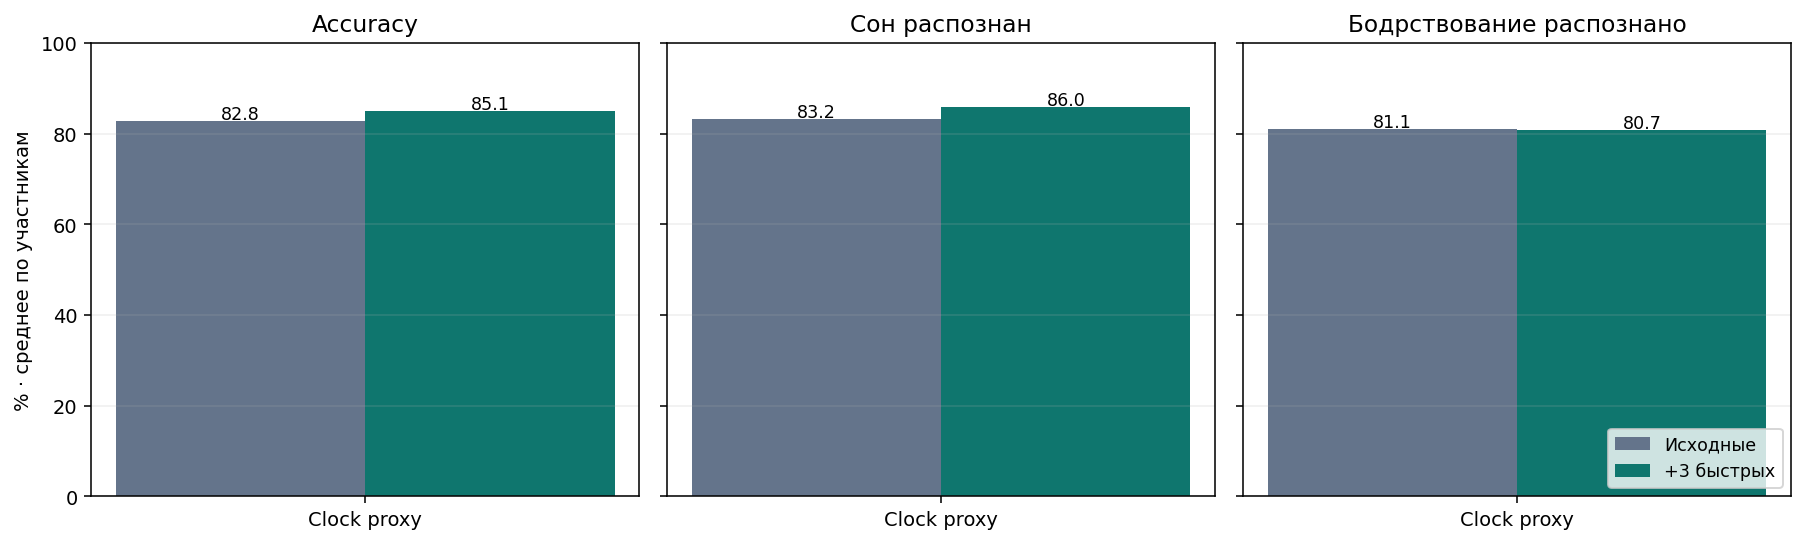

In [4]:
tradeoff = []
for base in ["Clock"]:
    a, b = means.loc[feature_set(base)], means.loc[feature_set(base, True)]
    tradeoff.append({"Время": base, **{TEXTS[m] + " · изменение, п.п.": 100 * (b[m] - a[m])
                    for m in ["accuracy", "sleep_correct", "wake_correct"]}})
display(pd.DataFrame(tradeoff).set_index("Время").round(2))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, metric in zip(axes, ["accuracy", "sleep_correct", "wake_correct"]):
    for i, base in enumerate(["Clock"]):
        for extra, offset in [(False, -.18), (True, .18)]:
            key = "fast" if extra else "base"
            value = 100 * means.loc[feature_set(base, extra), metric]
            ax.bar(i + offset, value, width=.36, color=COLORS[key], label=TEXTS[key] if i == 0 else None)
            ax.text(i + offset, value + .4, f"{value:.1f}", ha="center", fontsize=9)
    ax.set_xticks([0], ["Clock proxy"])
    ax.set_title(TEXTS[metric])
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("% · среднее по участникам")
axes[-1].legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "class_tradeoff.png", dpi=180)
plt.show()


При добавлении признаков основное изменение — **лучшее распознавание сна**. Среднее распознавание бодрствования почти сохраняется: оно немного снижается: 81,1% → 80,7%. Поэтому фраза «новые признаки улучшают распознавание бодрствования» не описывает этот результат при пороге 0,5.


## 3. Улучшение не одинаково для всех

Ниже — парные изменения κ у каждого человека. Положительное значение означает улучшение при добавлении признаков. Расчёт использует одних и тех же участников в обоих вариантах.


,Время,Метрика,Среднее изменение,Улучшилось участников,Всего,95% интервал · низ,95% интервал · верх
0,Clock,ROC AUC,0.0100,21,31,0.0015,0.0182
1,Clock,Cohen κ,0.0323,26,31,0.0126,0.0525


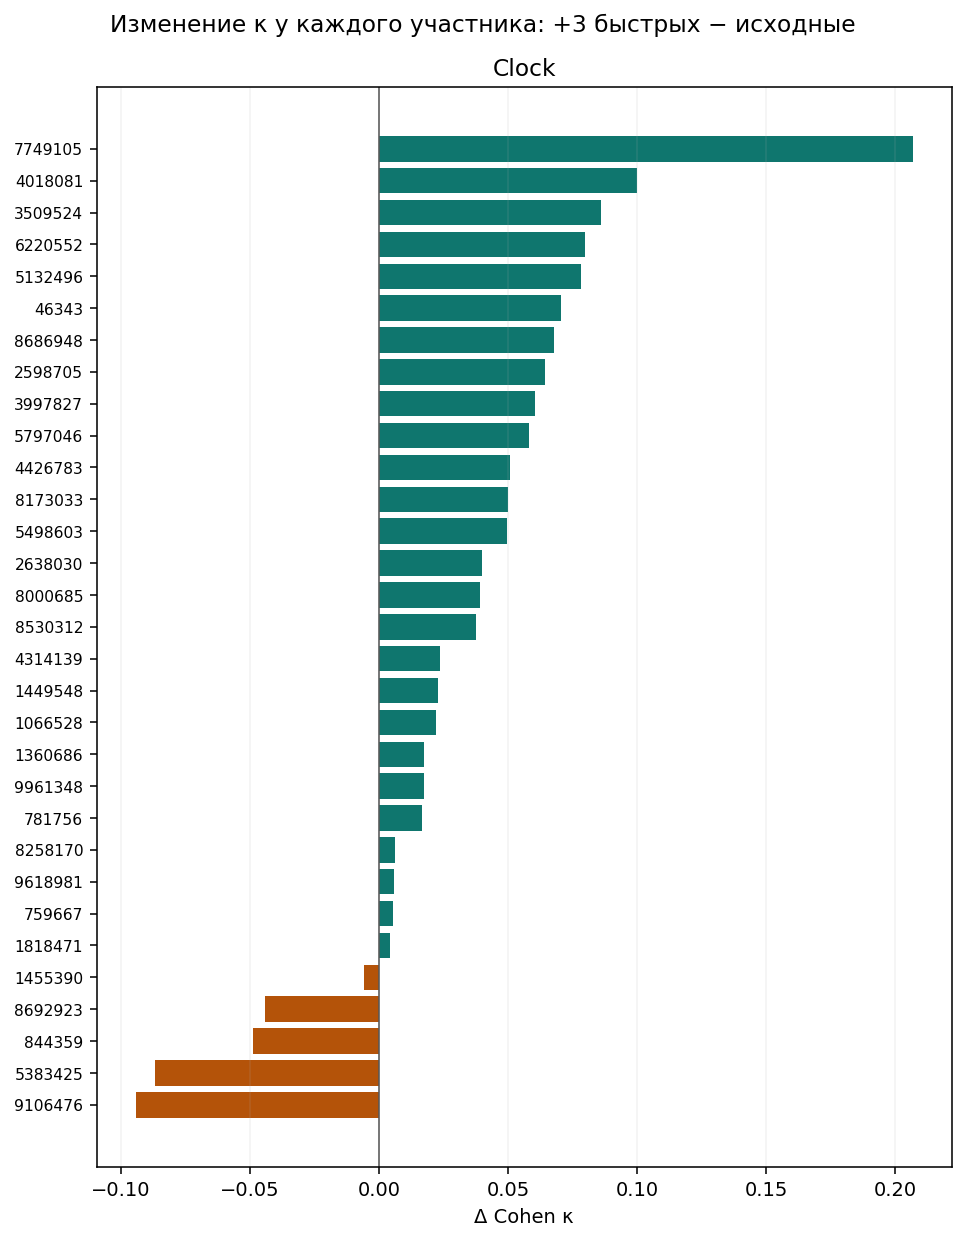

In [5]:
deltas = {}
analysis_rows = []
rng = np.random.default_rng(42)
for base in ["Clock"]:
    for metric in ["auc", "kappa"]:
        paired = participant[participant.feature_set.isin([feature_set(base), feature_set(base, True)])].pivot(index="subject", columns="feature_set", values=metric)
        delta = paired[feature_set(base, True)] - paired[feature_set(base)]
        deltas[(base, metric)] = delta
        draws = rng.choice(delta.to_numpy(), size=(10000, len(delta)), replace=True).mean(axis=1)
        lo, hi = np.quantile(draws, [.025, .975])
        analysis_rows.append({"Время": base, "Метрика": TEXTS[metric], "Среднее изменение": delta.mean(),
                              "Улучшилось участников": int((delta > 0).sum()), "Всего": len(delta),
                              "95% интервал · низ": lo, "95% интервал · верх": hi})
paired_analysis = pd.DataFrame(analysis_rows)
display(paired_analysis.round(4))
fig, axes = plt.subplots(1, 1, figsize=(7, 9))
for ax, base in zip(np.atleast_1d(axes), ["Clock"]):
    delta = deltas[(base, "kappa")].sort_values()
    colors = [COLORS["fast"] if v >= 0 else "#b45309" for v in delta]
    ax.barh(range(len(delta)), delta.to_numpy(), color=colors)
    ax.set_yticks(range(len(delta)), delta.index, fontsize=8)
    ax.axvline(0, color="#555555", linewidth=.8)
    ax.set_title(base)
    ax.set_xlabel("Δ " + TEXTS["kappa"])
    ax.grid(axis="x", alpha=.15)
fig.suptitle(TEXTS["delta_title"])
fig.tight_layout()
fig.savefig(EXPORT_DIR / "participant_deltas.png", dpi=180)
plt.show()


Интервалы получены описательным bootstrap по участникам: 10 000 повторных выборок парных различий. Они не учитывают весь предыдущий поиск признаков и моделей на этой выборке. Это оценка разброса наблюдаемого эффекта, а не подтверждение переноса на новую популяцию.


## 4. ROC и Precision–Recall

Теперь объединяем все отложенные эпохи. Здесь каждый человек получает вес в соответствии с длиной записи. Для PR положительный класс — **бодрствование**, чтобы показать качество распознавания редкого класса.


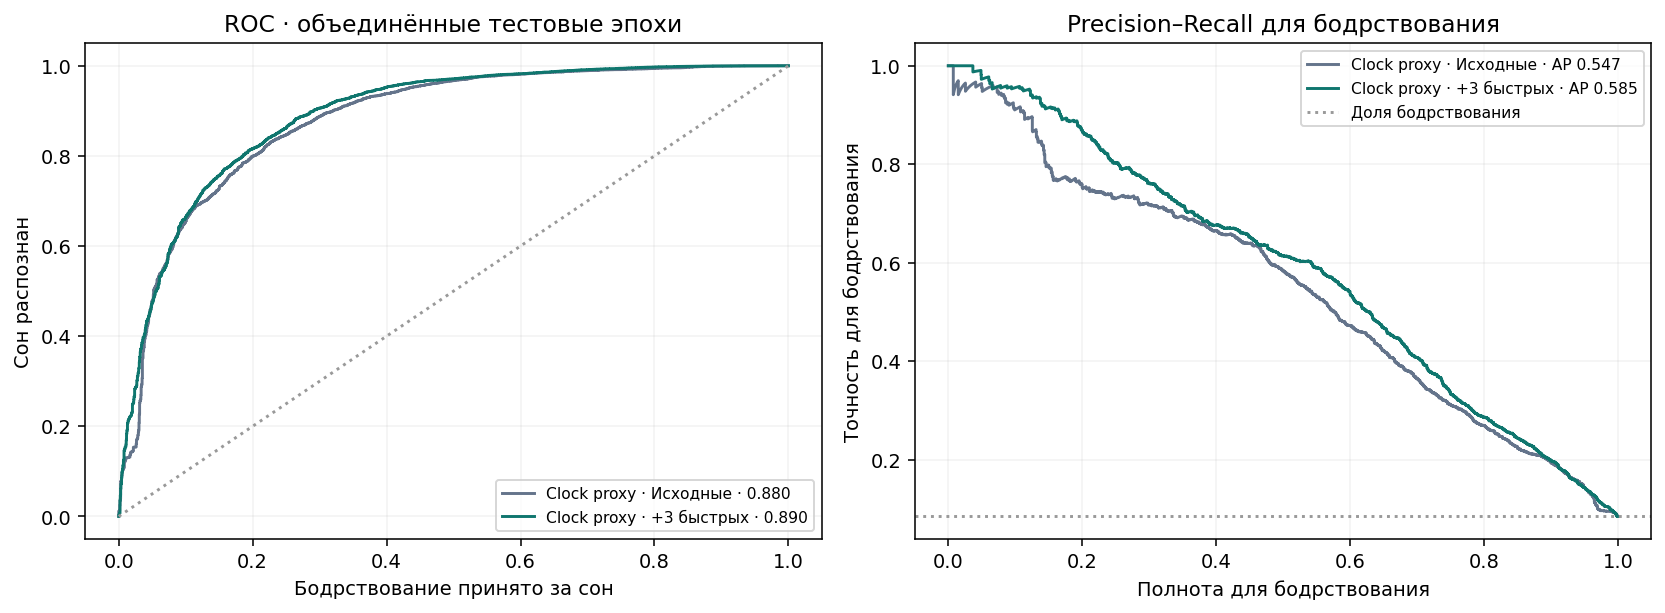

,Набор,AUC · все эпохи,AP бодрствования
0,"Motion, HR, Clock",0.8799,0.5466
1,"Motion, HR, Clock + быстрые",0.8896,0.5852


In [6]:
y = arrays["y"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
curve_rows = []
for name in snapshot["manifest"]["feature_sets"]:
    p = arrays[name]
    color = COLORS["fast" if "быстрые" in name else "base"]
    style = "-"
    auc = roc_auc_score(y, p)
    ap = average_precision_score(1 - y, 1 - p)
    fpr, tpr, _ = roc_curve(y, p)
    precision, recall, _ = precision_recall_curve(1 - y, 1 - p)
    axes[0].plot(fpr, tpr, color=color, linestyle=style, label=f"{name_for(name)} · {auc:.3f}")
    axes[1].plot(recall, precision, color=color, linestyle=style, label=f"{name_for(name)} · AP {ap:.3f}")
    curve_rows.append({"Набор": name, "AUC · все эпохи": auc, "AP бодрствования": ap})
axes[0].plot([0, 1], [0, 1], ":", color="#999999")
axes[1].axhline((1 - y).mean(), linestyle=":", color="#999999", label="Доля бодрствования")
axes[0].set(title=TEXTS["roc_title"], xlabel="Бодрствование принято за сон", ylabel="Сон распознан")
axes[1].set(title=TEXTS["pr_title"], xlabel="Полнота для бодрствования", ylabel="Точность для бодрствования")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "roc_pr.png", dpi=180)
plt.show()
display(pd.DataFrame(curve_rows).round(4))


**Почему AUC здесь отличается от первой таблицы?** Средний AUC по людям оценивает разделение классов внутри каждой записи. Объединённый AUC также сравнивает вероятности эпох разных участников. Это разные расчёты; нельзя смешивать их в одной строке сравнения. κ также нелинейна: κ общей матрицы ошибок отличается от среднего κ отдельных людей.


## 5. Матрицы ошибок при пороге 0,5

Строки — истинный класс, столбцы — предсказанный. Цвет и проценты нормированы по строке; абсолютное число эпох показано в каждой клетке.


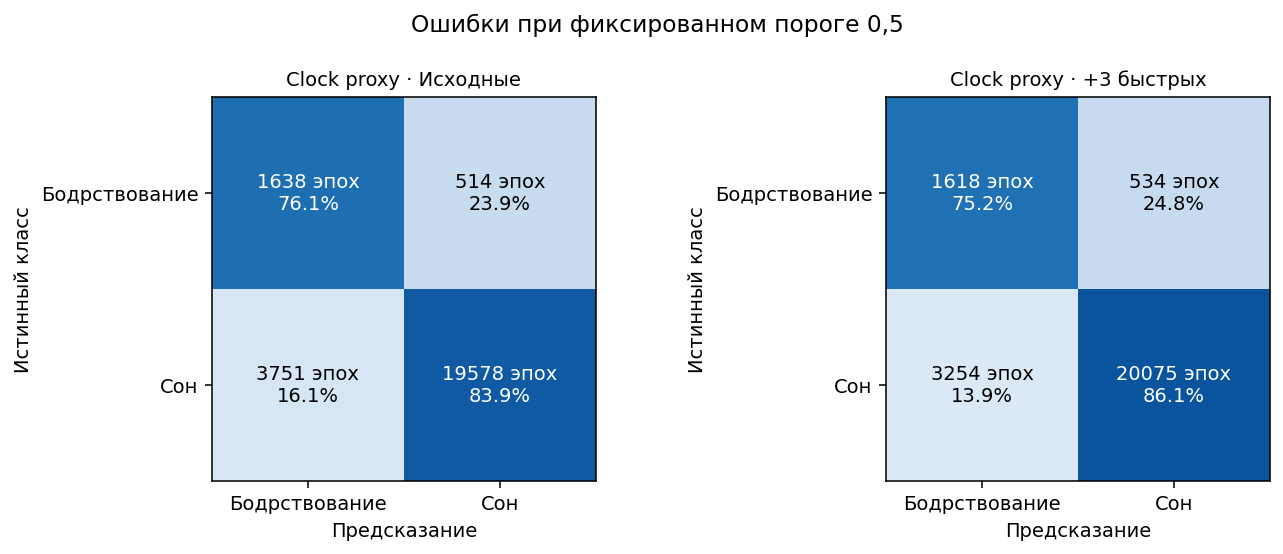

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes.flat, snapshot["manifest"]["feature_sets"]):
    matrix = confusion_matrix(y, arrays[name] >= .5, labels=[0, 1])
    fractions = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{matrix[row, col]} эпох\n{fractions[row, col]:.1%}", ha="center", va="center",
                    color="white" if fractions[row, col] > .5 else "black")
    ax.set_xticks([0, 1], ["Бодрствование", "Сон"])
    ax.set_yticks([0, 1], ["Бодрствование", "Сон"])
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истинный класс")
    ax.set_title(name_for(name), fontsize=10)
fig.suptitle(TEXTS["confusion_title"])
fig.tight_layout()
fig.savefig(EXPORT_DIR / "confusion_matrices.png", dpi=180)
plt.show()


## 6. Описательные результаты при 90% распознанного сна

В исходном скрипте порог для этой таблицы выбирается **по истинным тестовым меткам**, чтобы получить заданную чувствительность. Это анализ возможного рабочего режима, как в таблицах статьи. Он не показывает результат заранее выбранного порога и не должен подменять оценку при 0,5.


In [8]:
display(pooled[["feature_set", "accuracy@90", "wake_correct@90", "kappa@90", "f1_wake@90"]].round(4))


,feature_set,accuracy@90,wake_correct@90,kappa@90,f1_wake@90
0,"Motion, HR, Clock",0.8814,0.6803,0.4308,0.4922
1,"Motion, HR, Clock + быстрые",0.8839,0.7086,0.4477,0.5076


## Вывод

Три дополнительных признака улучшили CatBoost с clock proxy. κ улучшилась у 26 из 31 участника. При пороге 0,5 улучшение главным образом связано с распознаванием сна; эффект различается между участниками.

Ограничения:

- Использованы фиксированные настройки на 100 деревьев; результаты не характеризуют все возможные настройки CatBoost.
- Выборка уже использовалась для исследования других моделей и признаков. Нужна независимая внешняя проверка.
- Медиана пульса и центрированные окна используют будущие данные: анализ предназначен для готовой записи.
- С прежним MLP числа напрямую не сопоставимы: отличаются разбиения, веса классов и настройки. Для сравнения моделей нужен общий протокол.
- Этот анализ оценивает три добавки вместе. Вклад каждого признака в прибавку качества отдельно не установлен.

## Веса и воспроизведение

Финальные модели и JSON с порядком входов лежат в [репозитории](https://github.com/AlisaPopova25/ai_school_october/tree/main/results/catboost_clock_proxy). Этот ноутбук не использует финальные веса для оценки и не запускает обучение.

Для повторного обучения только с Clock: `python repro/10_fast_features.py --models CatBoost --base Clock`.
Пересборка этого ноутбука использует опубликованные отложенные предсказания: `python repro/build_catboost_clock_notebook.py`.


In [9]:
# Сохранить все таблицы анализа рядом с графиками.
participant.to_csv(EXPORT_DIR / "participant_metrics.csv", index=False)
means.to_csv(EXPORT_DIR / "participant_mean_metrics.csv")
paired_analysis.to_csv(EXPORT_DIR / "paired_changes.csv", index=False)
pooled.to_csv(EXPORT_DIR / "pooled_metrics.csv", index=False)
print("Графики и таблицы сохранены в:", EXPORT_DIR)


Графики и таблицы сохранены в: C:\Users\Lenovo\Documents\ChatGPT\ПШ - 2\ai_school_october\results\catboost_clock_proxy\analysis_exports
